# 02 · Body baseline models: is today abnormal for *this* person?

**Questions**
1. Which detector raises the fewest false alarms on real people and still catches a planted change fastest?
2. Do the methods complement each other (spikes vs slow drifts vs odd combinations)?
3. Which single signals carry the detection value?
4. Which **combination** should the engine use, and at which parameters?

**Inputs:** `data/processed/pmdata_daily.parquet` (real PMData, 14 usable people; notebook 01).
**Outputs:** comparison tables, trade-off figures `reports/figures/02_*.png`, and the chosen body-model parameters in `models/engine_config.json`.

**Protocol** (shared, `docs/NOTEBOOKS.md`): false alarms per person-month on the real series (14-day warm-up, injury days ±2 excluded,
consecutive alert days = one episode) and detection delay on changes planted into the real series (200 per change type, missed if not caught within 14 days).
Target: **at most 1 false alarm per person-month**.

**Conventions fixed after notebook 01** (agreed with the team in chat):
- All signals are flipped into *badness* units, so a positive z always means worse (PMSys self-reports are 5 = best).
- The self-reports are 1–5 integers whose MAD is usually 0, so their robust scale falls back to the mean absolute deviation, with a floor of half a scale point.
- A planted change counts as detected only by an alert the untouched series did not already have.

In [1]:
import sys
sys.path.insert(0, "../ml")
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import Parallel, delayed
from scipy import stats
from sol_ml.nbutil import *
from sol_ml.detectors import body, evaluation
from sol_ml.detectors.baseline import BODY_SIGNALS, zscores
from sol_ml.detectors.evaluation import INJECTIONS

rng = setup()
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore")
TARGET_FA = 1.0
N_INJECTIONS = 200
CASES = list(INJECTIONS)

daily = pd.read_parquet(PROCESSED / "pmdata_daily.parquet")
names = [p for p in sorted(daily.person.unique()) if p not in ("p12", "p13")]
people = evaluation.load_people(daily, names)
sites = {name: evaluation.sample_sites(people, name, N_INJECTIONS, rng) for name in CASES}
months = sum(p.mask.sum() for p in people) / 30
print(len(people), "people,", round(months, 1), "evaluated person-months,", N_INJECTIONS, "planted changes per case")
pd.DataFrame([p.scales for p in people], index=names, columns=BODY_SIGNALS).round(2).T

14 people, 60.1 evaluated person-months, 200 planted changes per case


,p01,p02,p03,p04,p05,p06,p07,p08,p09,p10,p11,p14,p15,p16
resting_hr,1.35,1.50,2.12,2.97,3.24,1.90,2.15,2.41,3.20,2.08,2.13,3.55,1.69,1.69
sleep_minutes,43.74,42.25,65.23,62.27,51.89,51.15,49.67,41.51,111.20,51.89,54.86,112.68,60.79,77.10
fatigue,0.56,0.50,0.50,0.59,0.50,0.50,0.50,0.82,1.48,1.48,0.50,0.50,1.48,0.50
mood,0.50,0.50,0.50,0.72,0.65,0.50,0.50,0.50,0.74,0.50,0.50,0.50,0.63,0.50
stress,0.50,0.50,0.50,1.48,0.74,0.61,1.48,1.48,1.48,1.48,0.50,0.50,0.61,0.55


## 1. What the planted changes look like

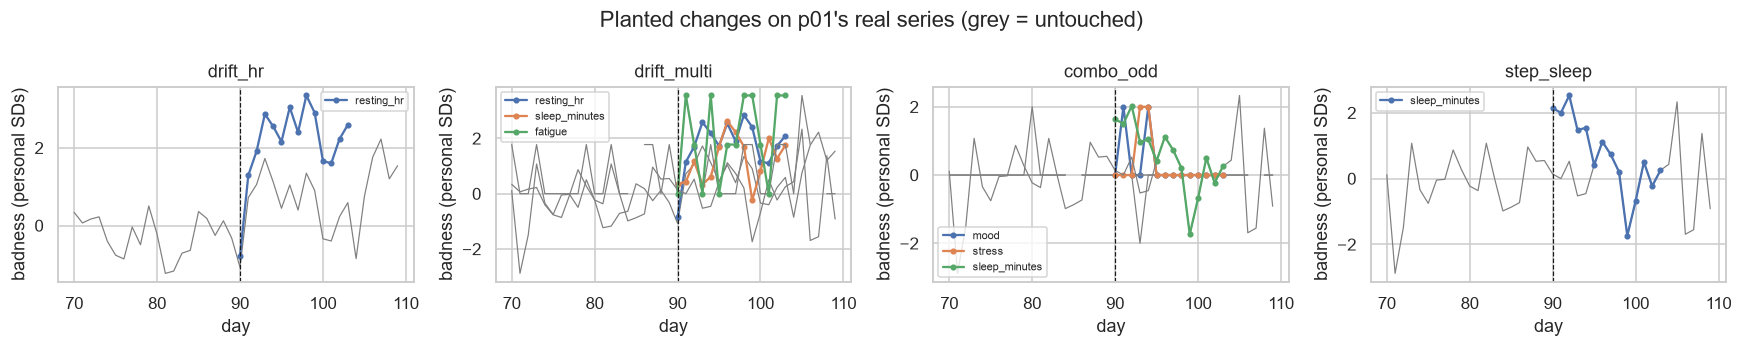

In [2]:
p = people[0]
start = 90
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, case in zip(axes, CASES):
    planted = evaluation.inject(p.X, case, start, p.scales, np.random.default_rng(SEED))
    cols = INJECTIONS[case][0]
    for j in cols:
        sign = 1 if BODY_SIGNALS[j] == "resting_hr" else -1
        z_clean, z_new = (p.X[:, j] - np.nanmedian(p.X[:, j])) / p.scales[j], (planted[:, j] - np.nanmedian(p.X[:, j])) / p.scales[j]
        ax.plot(range(start - 20, start + 20), z_clean[start - 20:start + 20], color="grey", lw=0.8)
        ax.plot(range(start, start + 14), z_new[start:start + 14], marker="o", ms=3, label=BODY_SIGNALS[j])
    ax.axvline(start, color="k", ls="--", lw=0.8)
    ax.set(title=case, xlabel="day", ylabel="badness (personal SDs)")
    ax.legend(fontsize=7)
fig.suptitle(f"Planted changes on {p.name}'s real series (grey = untouched)")
savefig("02_planted_changes");

## 2. Are personal z-scores well behaved on real data?
Limits such as "alert at z > 3" assume roughly normal, independent z-scores. Check that on the untouched data.

In [3]:
rows = []
for window in (7, 14, 28):
    Z = np.vstack([zscores(p.X, window)[p.mask] for p in people])
    for j, s in enumerate(BODY_SIGNALS):
        z = Z[:, j][~np.isnan(Z[:, j])]
        rows.append({"window": window, "signal": s, "sd_of_z": z.std(), "share_z>3": (z > 3).mean(), "share_z<-3": (z < -3).mean(),
                     "normal_would_be": stats.norm.sf(3)})
tails = pd.DataFrame(rows).set_index(["window", "signal"]).round(4)
tails

sd_of_z  share_z>3  share_z<-3  normal_would_be
window signal                                                        
7      resting_hr      2.6906     0.0757      0.0738           0.0013
       sleep_minutes   3.0457     0.0552      0.0643           0.0013
       fatigue         1.1887     0.0061      0.0104           0.0013
       mood            1.0166     0.0113      0.0061           0.0013
       stress          1.1499     0.0148      0.0078           0.0013
14     resting_hr      1.8156     0.0407      0.0300           0.0013
       sleep_minutes   1.8420     0.0304      0.0349           0.0013
       fatigue         1.1017     0.0085      0.0123           0.0013
       mood            0.9403     0.0054      0.0054           0.0013
       stress          1.0834     0.0139      0.0039           0.0013
28     resting_hr      1.3969     0.0276      0.0178           0.0013
       sleep_minutes   1.4995     0.0312      0.0260           0.0013
       fatigue         1.0510     0.0087      0.0087           0.0013
       mood            0.8770     0.0055      0.0032           0.0013
       stress          1.0080     0.0095      0.0016           0.0013

## 3. Sweep every candidate

In [4]:
specs = []
for sided in ("worse", "both"):
    specs += [dict(kind="population_z", thr=t, sided=sided) for t in (2.0, 2.5, 3.0, 3.5, 4.0, 5.0)]
    specs += [dict(kind="personal_z", window=w, thr=t, sided=sided) for w in (7, 14, 28) for t in (2.5, 3.0, 3.5, 4.0, 5.0, 6.0)]
specs += [dict(kind="cusum", window=w, k=k, h=h) for w in (14, 28) for k in (0.5, 1.0, 1.5) for h in (3.0, 4.0, 5.0, 6.0, 8.0, 10.0, 14.0)]
specs += [dict(kind="ewma", window=w, lam=l, L=L) for w in (14, 28) for l in (0.1, 0.2, 0.3) for L in (2.5, 3.0, 3.5, 4.0, 5.0, 6.0)]
RATES = (0.005, 0.01, 0.02, 0.05, 0.1, 0.2)
specs += [dict(kind=kind, mode=mode, window=14, rate=r) for kind in ("iforest", "mahalanobis") for mode in ("pooled", "rolling") for r in RATES]
specs += [dict(kind="lof", mode="pooled", window=14, rate=r) for r in RATES]
print(len(specs), "configurations x", len(CASES) * N_INJECTIONS, "planted runs each")

def run_all(spec_list):
    return pd.DataFrame(Parallel(n_jobs=-1)(delayed(body.run_spec)(s, people, sites, SEED) for s in spec_list))

sweep = cached("nb02_sweep", [specs, sites], lambda: run_all(specs))
sweep["family"] = sweep.kind + np.where(sweep["mode"].notna(), " (" + sweep["mode"].fillna("") + ")", "") \
    + np.where(sweep.sided.eq("both"), " two-sided", "")
sweep.groupby("family").false_alarms.agg(["count", "min", "max"]).round(2)

156 configurations x 800 planted runs each


,count,min,max
family,,,
cusum,42,0.03,1.18
ewma,36,0.15,1.81
iforest (pooled),6,0.12,1.71
iforest (rolling),6,0.08,1.18
lof (pooled),6,0.07,2.01
mahalanobis (pooled),6,0.15,2.25
mahalanobis (rolling),6,0.03,1.38
personal_z,18,0.08,3.06
personal_z two-sided,18,0.13,5.07


In [5]:
LETTER = {"population_z": "A", "personal_z": "B", "cusum": "C", "ewma": "D", "iforest": "E", "mahalanobis": "F", "lof": "G"}
PARAMS = ["window", "thr", "sided", "k", "h", "lam", "L", "mode", "rate"]

def describe(row):
    return ", ".join(f"{k}={row[k]:g}" if isinstance(row[k], float) else f"{k}={row[k]}" for k in PARAMS
                     if k in row and pd.notna(row[k]) and not (k == "sided" and row[k] == "worse"))

def best_under(df, budget=TARGET_FA):
    ok = df[df.false_alarms <= budget]
    return ok.sort_values(["mean_delay", "mean_miss", "false_alarms"]).iloc[0] if len(ok) else None

rows = []
for family, g in sweep.groupby("family"):
    b = best_under(g)
    if b is None:
        rows.append({"model": LETTER[g.kind.iloc[0]], "family": family, "setting": "no setting reaches the target",
                     "false_alarms": g.false_alarms.min()})
        continue
    rows.append({"model": LETTER[b.kind], "family": family, "setting": describe(b), "false_alarms": b.false_alarms,
                 **{f"{c} (days / miss)": f"{b[c + '_delay_hit']:.0f} / {b[c + '_miss']:.0%}" for c in CASES},
                 "mean_delay": b.mean_delay, "mean_miss": b.mean_miss})
best = pd.DataFrame(rows).sort_values(["mean_delay", "mean_miss"]).reset_index(drop=True)
print("Fastest setting of each family with at most", TARGET_FA, "false alarm per person-month.")
print("days = median delay of the caught cases; miss = share not caught within 14 days; mean_delay counts a miss as 14 days.")
best.round(2)

Fastest setting of each family with at most 1.0 false alarm per person-month.
days = median delay of the caught cases; miss = share not caught within 14 days; mean_delay counts a miss as 14 days.


,model,family,setting,false_alarms,drift_hr (days / miss),drift_multi (days / miss),combo_odd (days / miss),step_sleep (days / miss),mean_delay,mean_miss
0,D,ewma,"window=28, lam=0.3, L=3.5",0.93,5 / 22%,5 / 8%,2 / 70%,2 / 48%,7.25,0.37
1,C,cusum,"window=28, k=1, h=3",0.93,6 / 26%,5 / 22%,2 / 62%,2 / 41%,7.50,0.38
2,E,iforest (pooled),"window=14, mode=pooled, rate=0.1",0.87,3 / 78%,5 / 52%,1 / 33%,1 / 82%,11.00,0.61
3,E,iforest (rolling),"window=14, mode=rolling, rate=0.1",0.55,4 / 84%,4 / 60%,1 / 46%,1 / 84%,11.50,0.68
4,G,lof (pooled),"window=14, mode=pooled, rate=0.1",0.98,4 / 71%,5 / 38%,2 / 62%,3 / 72%,12.50,0.61
5,F,mahalanobis (rolling),"window=14, mode=rolling, rate=0.1",0.78,5 / 80%,5 / 60%,0 / 52%,1 / 81%,14.00,0.68
6,B,personal_z,"window=14, thr=4",0.75,4 / 68%,5 / 62%,1 / 84%,0 / 75%,14.00,0.72
7,B,personal_z two-sided,"window=28, thr=4, sided=both",0.75,4 / 72%,5 / 74%,1 / 84%,1 / 76%,14.00,0.77
8,F,mahalanobis (pooled),"window=14, mode=pooled, rate=0.05",0.47,4 / 92%,4 / 71%,1 / 68%,0 / 88%,14.00,0.80
9,A,population_z,thr=4,0.15,nan / 100%,8 / 83%,2 / 92%,1 / 86%,14.00,0.90


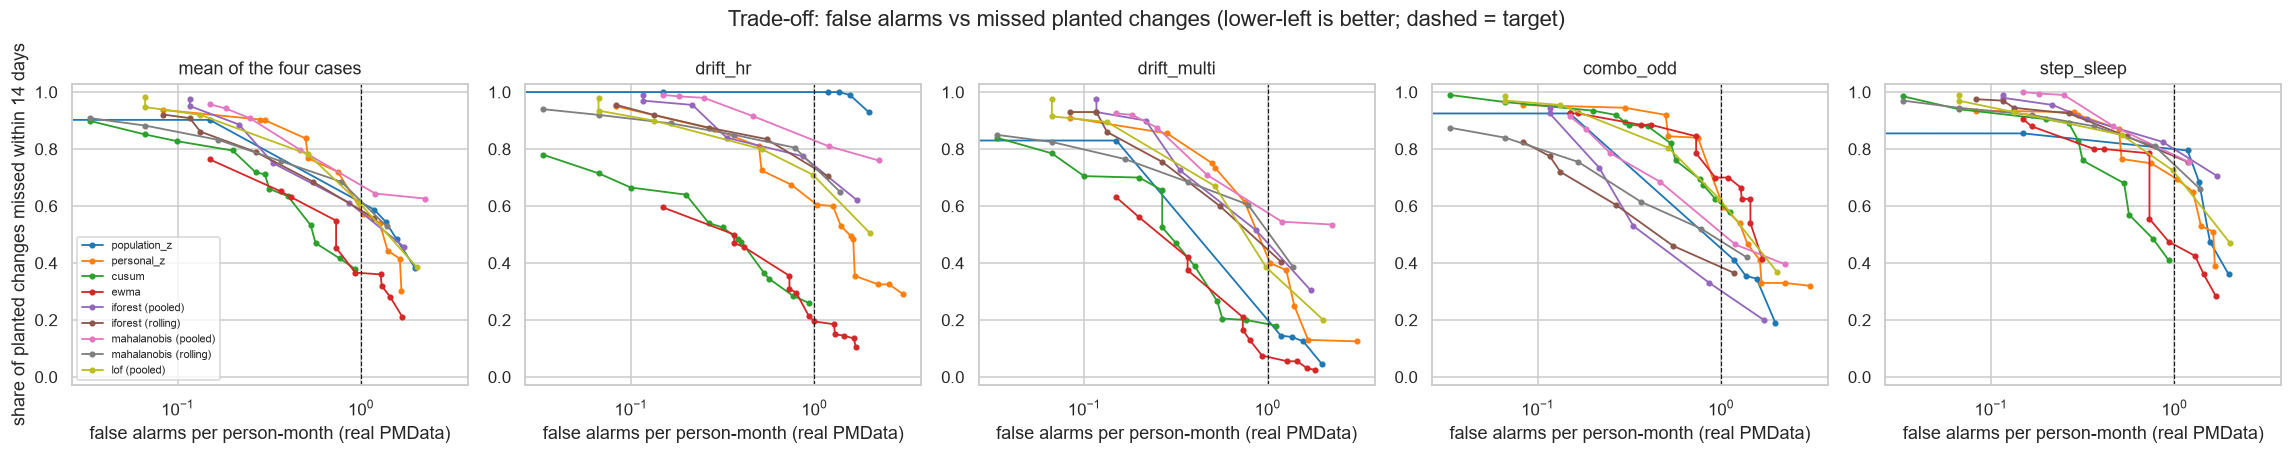

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(21, 4.2), sharex=True)
families = [f for f in sweep.family.unique() if "two-sided" not in f]
palette = dict(zip(families, sns.color_palette("tab10", len(families))))
for ax, col, title in zip(axes, ["mean_miss"] + [c + "_miss" for c in CASES], ["mean of the four cases"] + CASES):
    for family in families:
        g = sweep[sweep.family == family].sort_values("false_alarms")
        frontier = g[g[col] <= g[col].cummin()]                 # best miss rate at each false-alarm level
        ax.plot(frontier.false_alarms, frontier[col], marker="o", ms=3, lw=1.2, color=palette[family], label=family)
    ax.axvline(TARGET_FA, color="k", ls="--", lw=0.8)
    ax.set(title=title, xlabel="false alarms per person-month (real PMData)", xscale="log", ylim=(-0.03, 1.03))
axes[0].set_ylabel("share of planted changes missed within 14 days")
axes[0].legend(fontsize=7)
fig.suptitle("Trade-off: false alarms vs missed planted changes (lower-left is better; dashed = target)")
savefig("02_tradeoff_miss");

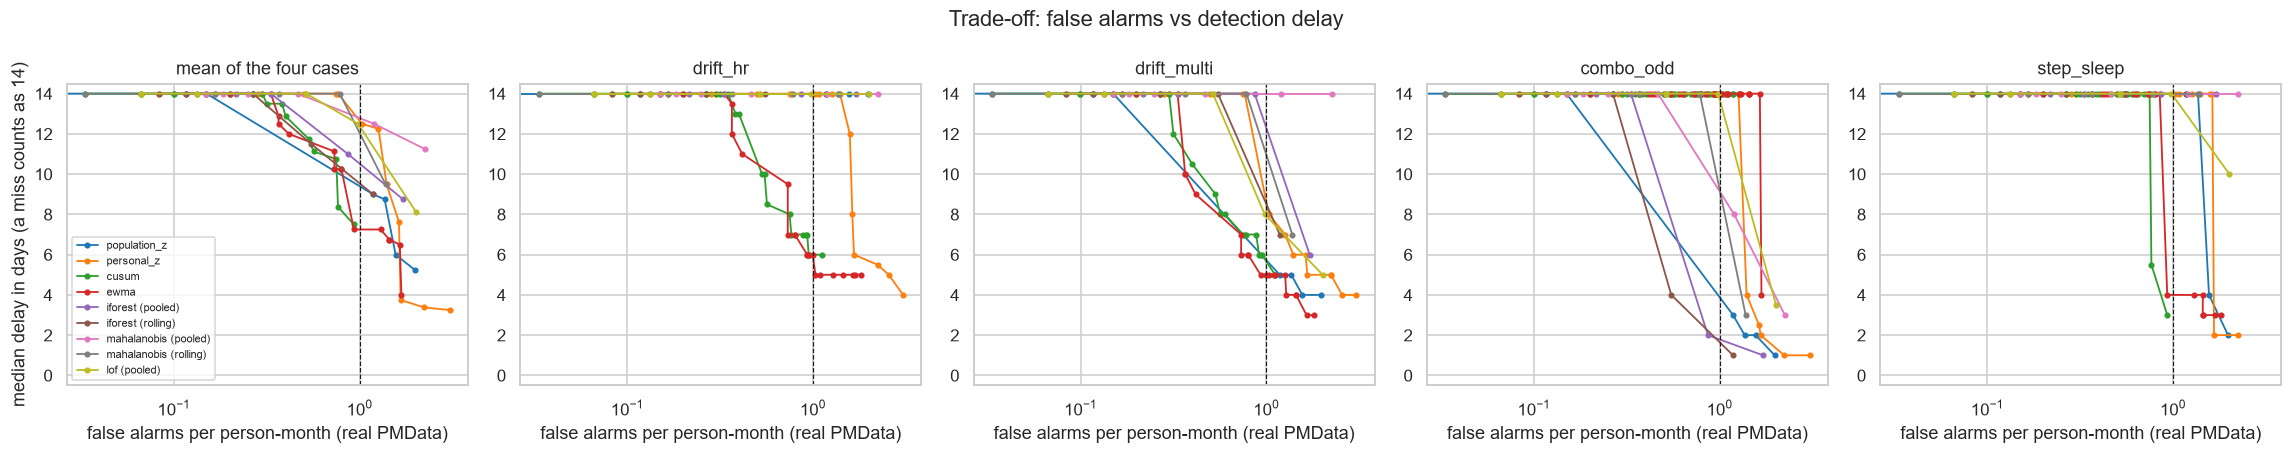

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(21, 4.2), sharex=True)
for ax, col, title in zip(axes, ["mean_delay"] + [c + "_delay" for c in CASES], ["mean of the four cases"] + CASES):
    for family in families:
        g = sweep[sweep.family == family].sort_values("false_alarms")
        frontier = g[g[col] <= g[col].cummin()]
        ax.plot(frontier.false_alarms, frontier[col], marker="o", ms=3, lw=1.2, color=palette[family], label=family)
    ax.axvline(TARGET_FA, color="k", ls="--", lw=0.8)
    ax.set(title=title, xlabel="false alarms per person-month (real PMData)", xscale="log", ylim=(-0.5, 14.5))
axes[0].set_ylabel("median delay in days (a miss counts as 14)")
axes[0].legend(fontsize=7)
fig.suptitle("Trade-off: false alarms vs detection delay")
savefig("02_tradeoff_delay");

## 4. One-sided or two-sided, and does the personal baseline beat the population one?

In [8]:
cmp = sweep[sweep.kind.isin(["personal_z", "population_z"])].copy()
cmp["sided"] = cmp.sided.fillna("worse")
rows = []
for (kind, sided), g in cmp.groupby(["kind", "sided"]):
    b = best_under(g)
    rows.append({"kind": kind, "sided": sided, "setting": describe(b) if b is not None else "-",
                 "false_alarms": b.false_alarms if b is not None else g.false_alarms.min(),
                 **({c + "_miss": b[c + "_miss"] for c in CASES} if b is not None else {}),
                 "mean_delay": b.mean_delay if b is not None else np.nan})
pd.DataFrame(rows).round(2)

,kind,sided,setting,false_alarms,drift_hr_miss,drift_multi_miss,combo_odd_miss,step_sleep_miss,mean_delay
0,personal_z,both,"window=28, thr=4, sided=both",0.75,0.72,0.74,0.84,0.76,14.0
1,personal_z,worse,"window=14, thr=4",0.75,0.68,0.62,0.84,0.75,14.0
2,population_z,both,"thr=4, sided=both",0.23,1.00,0.83,0.92,0.86,14.0
3,population_z,worse,thr=4,0.15,1.00,0.83,0.92,0.86,14.0


## 5. Do the methods complement each other?
Each family at its own best setting under the target: which planted changes does it miss?

,drift_hr,drift_multi,combo_odd,step_sleep
cusum,0.26,0.22,0.62,0.41
ewma,0.22,0.08,0.70,0.48
iforest (pooled),0.78,0.52,0.33,0.82
iforest (rolling),0.84,0.60,0.46,0.84
lof (pooled),0.71,0.38,0.62,0.72
mahalanobis (pooled),0.92,0.71,0.68,0.88
mahalanobis (rolling),0.80,0.60,0.52,0.81
personal_z,0.68,0.62,0.84,0.75
population_z,1.00,0.83,0.92,0.86


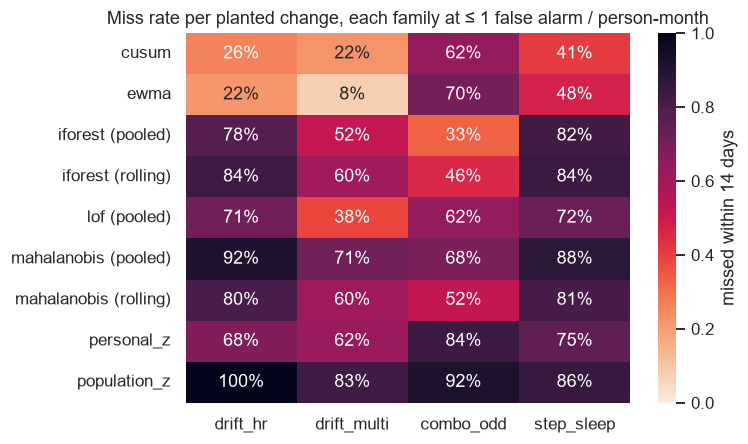

In [9]:
points = {f: best_under(g) for f, g in sweep[~sweep.family.str.contains("two-sided")].groupby("family")}
points = {f: b for f, b in points.items() if b is not None}
miss = pd.DataFrame({f: [b[c + "_miss"] for c in CASES] for f, b in points.items()}, index=CASES).T
fig, ax = plt.subplots(figsize=(7, 4.2))
sns.heatmap(miss, annot=True, fmt=".0%", cmap="rocket_r", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "missed within 14 days"})
ax.set_title(f"Miss rate per planted change, each family at ≤ {TARGET_FA:g} false alarm / person-month")
savefig("02_complementarity");
miss.round(2)

## 6. Which single signals carry the detection value? (ablation)
The best univariate settings are re-run on one signal at a time.

In [10]:
def spec_of(row, **extra):
    spec = {"kind": row.kind}
    for k in PARAMS:
        if k in row and pd.notna(row[k]):
            spec[k] = int(row[k]) if k == "window" else row[k]
    spec.update(extra)
    return spec

abl_specs, labels = [], []
for family in ("personal_z", "cusum", "ewma"):
    if family not in points:
        continue
    for j, s in enumerate(BODY_SIGNALS):
        abl_specs.append(spec_of(points[family], cols=[j])); labels.append((family, s))
    abl_specs.append(spec_of(points[family], cols=list(range(5)))); labels.append((family, "all five"))
abl = cached("nb02_ablation", [abl_specs, sites], lambda: run_all(abl_specs))
abl.index = pd.MultiIndex.from_tuples(labels, names=["detector", "signal"])
abl[["false_alarms"] + [c + "_miss" for c in CASES]].round(2)

false_alarms  drift_hr_miss  drift_multi_miss  combo_odd_miss  step_sleep_miss
detector   signal                                                                                       
personal_z resting_hr             0.30           0.68              0.72            1.00             1.00
           sleep_minutes          0.47           1.00              0.84            0.87             0.75
           fatigue                0.00           1.00              1.00            1.00             1.00
           mood                   0.00           1.00              1.00            0.99             1.00
           stress                 0.00           1.00              1.00            0.96             1.00
           all five               0.75           0.68              0.62            0.84             0.75
cusum      resting_hr             0.45           0.26              0.34            1.00             1.00
           sleep_minutes          0.50           1.00              0.35            0.50             0.28
           fatigue                0.23           1.00              0.41            1.00             1.00
           mood                   0.20           1.00              1.00            0.66             1.00
           stress                 0.23           1.00              1.00            0.56             1.00
           all five               1.08           0.30              0.26            0.35             0.46
ewma       resting_hr             0.47           0.21              0.29            1.00             1.00
           sleep_minutes          0.40           1.00              0.44            0.66             0.42
           fatigue                0.22           1.00              0.46            1.00             1.00
           mood                   0.10           1.00              1.00            0.72             1.00
           stress                 0.27           1.00              1.00            0.64             1.00
           all five               1.10           0.24              0.08            0.40             0.50

## 7. Combinations
The team's plan is **B for spikes + C for drifts + E for odd combinations**. The whole combination has to stay under the target,
so each member gets a share of the false-alarm budget. Every family contributes its fastest setting under several budgets, and all unions are evaluated.

In [11]:
BUDGETS = (0.15, 0.3, 0.5, 0.8)
def options(family):
    g = sweep[sweep.family == family]
    out = {}
    for b in BUDGETS:
        row = best_under(g, b)
        if row is not None:
            out[json.dumps(spec_of(row), sort_keys=True)] = spec_of(row)
    return list(out.values())

spike_opts = options("personal_z")
drift_opts = options("cusum") + options("ewma")
combo_opts = options("mahalanobis (pooled)") + options("iforest (pooled)")
members = []
for s in spike_opts:
    for d in drift_opts:
        members.append([s, d])
        members += [[s, d, m] for m in combo_opts]
members += [[d, m] for d in drift_opts for m in combo_opts]
combo_specs = [dict(kind="any_of", members=m) for m in members]
print(len(spike_opts), "spike x", len(drift_opts), "drift x", len(combo_opts), "combination options ->", len(combo_specs), "unions")
combos = cached("nb02_combos", [combo_specs, sites], lambda: run_all(combo_specs))
combos["members"] = [" + ".join(LETTER[m["kind"]] for m in ms) for ms in members]
combos["spec"] = [json.dumps(ms) for ms in members]
rows = []
for shape, g in combos.groupby("members"):
    b = best_under(g)
    if b is not None:
        rows.append({"combination": shape, "false_alarms": b.false_alarms,
                     **{f"{c} (days / miss)": f"{b[c + '_delay_hit']:.0f} / {b[c + '_miss']:.0%}" for c in CASES},
                     "mean_delay": b.mean_delay, "mean_miss": b.mean_miss, "spec": b.spec})
combo_best = pd.DataFrame(rows).sort_values(["mean_delay", "mean_miss"]).reset_index(drop=True)
combo_best.drop(columns="spec").round(2)

4 spike x 7 drift x 6 combination options -> 238 unions


,combination,false_alarms,drift_hr (days / miss),drift_multi (days / miss),combo_odd (days / miss),step_sleep (days / miss),mean_delay,mean_miss
0,B + C + E,0.98,6 / 26%,5 / 16%,2 / 46%,2 / 46%,5.50,0.34
1,C + E,0.83,6 / 27%,5 / 18%,2 / 46%,2 / 46%,5.62,0.35
2,B + D + E,0.88,5 / 28%,6 / 14%,1 / 44%,2 / 52%,7.50,0.35
3,D + E,0.88,5 / 28%,6 / 14%,1 / 45%,2 / 52%,7.50,0.35
4,B + C + F,1.00,6 / 28%,5 / 16%,2 / 54%,2 / 48%,8.00,0.36
5,C + F,1.00,6 / 28%,5 / 16%,2 / 54%,2 / 48%,8.00,0.36
6,B + C,0.97,6 / 28%,6 / 17%,2 / 67%,2 / 48%,8.12,0.40
7,B + D + F,0.90,5 / 31%,5 / 16%,2 / 63%,2 / 56%,10.25,0.42
8,D + F,0.90,5 / 31%,5 / 16%,2 / 64%,2 / 56%,10.25,0.42
9,B + D,0.83,5 / 31%,6 / 16%,2 / 77%,2 / 56%,10.25,0.45


best single family : ewma | window=28, lam=0.3, L=3.5 | FA 0.93, mean delay 7.2, mean miss 37%
best combination   : B + C + E | FA 0.98, mean delay 5.5, mean miss 34%
   {'kind': 'personal_z', 'window': 14, 'thr': 5.0, 'sided': 'worse'}
   {'kind': 'cusum', 'window': 28, 'k': 1.0, 'h': 4.0}
   {'kind': 'iforest', 'window': 14, 'mode': 'pooled', 'rate': 0.05}


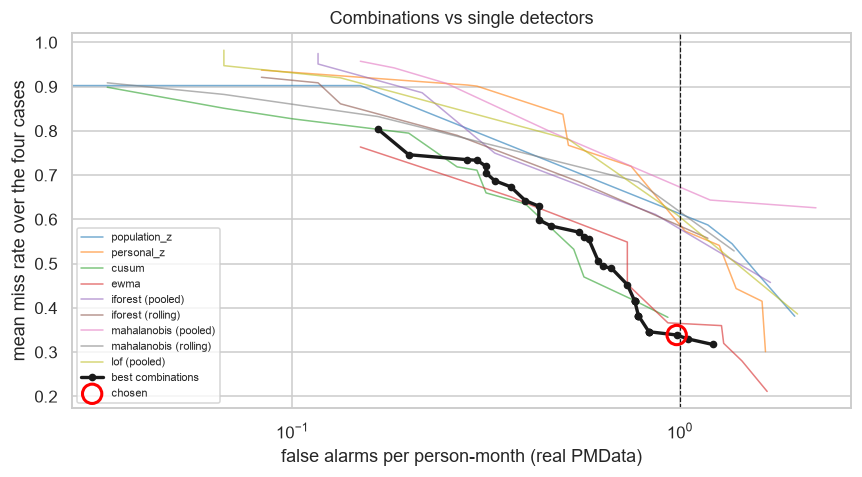

In [12]:
chosen = combo_best.iloc[0]
single = best.iloc[0]
print("best single family :", single.family, "|", single.setting, "| FA %.2f, mean delay %.1f, mean miss %.0f%%" % (single.false_alarms, single.mean_delay, 100 * single.mean_miss))
print("best combination   :", chosen.combination, "| FA %.2f, mean delay %.1f, mean miss %.0f%%" % (chosen.false_alarms, chosen.mean_delay, 100 * chosen.mean_miss))
chosen_members = json.loads(chosen.spec)
for m in chosen_members:
    print("  ", m)

fig, ax = plt.subplots(figsize=(8, 4.5))
for family in families:
    g = sweep[sweep.family == family].sort_values("false_alarms")
    f = g[g.mean_miss <= g.mean_miss.cummin()]
    ax.plot(f.false_alarms, f.mean_miss, lw=1, color=palette[family], alpha=0.6, label=family)
g = combos.sort_values("false_alarms")
f = g[g.mean_miss <= g.mean_miss.cummin()]
ax.plot(f.false_alarms, f.mean_miss, color="k", lw=2.2, marker="o", ms=4, label="best combinations")
ax.scatter([chosen.false_alarms], [chosen.mean_miss], s=160, facecolor="none", edgecolor="red", lw=2, zorder=5, label="chosen")
ax.axvline(TARGET_FA, color="k", ls="--", lw=0.8)
ax.set(xscale="log", xlabel="false alarms per person-month (real PMData)", ylabel="mean miss rate over the four cases",
       title="Combinations vs single detectors")
ax.legend(fontsize=7)
savefig("02_combination_vs_single");

## 8. How robust is the chosen combination across people?

In [13]:
detector = body.build(dict(kind="any_of", members=chosen_members), people)
rows = []
for p in people:
    alerts = detector(p, p.X)
    rows.append({"person": p.name, "evaluated_days": int(p.mask.sum()), "alert_episodes": evaluation.count_episodes(alerts & p.mask),
                 "alert_days": int((alerts & p.mask).sum())})
per_person = pd.DataFrame(rows).set_index("person")
per_person["false_alarms_per_month"] = (per_person.alert_episodes / (per_person.evaluated_days / 30)).round(2)
print("pooled: %.2f per person-month | worst person: %.2f | people above the target: %d of %d" % (
    per_person.alert_episodes.sum() / (per_person.evaluated_days.sum() / 30), per_person.false_alarms_per_month.max(),
    (per_person.false_alarms_per_month > TARGET_FA).sum(), len(per_person)))
per_person.T

pooled: 0.98 per person-month | worst person: 2.19 | people above the target: 6 of 14


person,p01,p02,p03,p04,p05,p06,p07,p08,p09,p10,p11,p14,p15,p16
evaluated_days,133.00,137.00,138.00,123.00,105.00,138.00,124.00,129.00,138.00,134.0,128.0,122.00,116.00,138.0
alert_episodes,3.00,10.00,3.00,7.00,4.00,3.00,6.00,4.00,2.00,0.0,3.0,6.00,2.00,6.0
alert_days,5.00,32.00,16.00,61.00,45.00,68.00,28.00,6.00,55.00,0.0,28.0,46.00,9.00,39.0
false_alarms_per_month,0.68,2.19,0.65,1.71,1.14,0.65,1.45,0.93,0.43,0.0,0.7,1.48,0.52,1.3


## 9. What the astronaut would read
Every alert has to explain itself in one sentence: the signal, how far from normal, and for how long.

In [14]:
LABEL = {"resting_hr": "resting heart rate", "sleep_minutes": "sleep", "fatigue": "fatigue score", "mood": "mood score", "stress": "stress score"}
WORSE = {"resting_hr": "above", "sleep_minutes": "below", "fatigue": "worse than", "mood": "worse than", "stress": "worse than"}

def reason(X, day, window):
    z = zscores(X, window)
    j = int(np.nanargmax(z[day]))
    run = 0
    while day - run >= 0 and (z[day - run, j] > 1 or np.isnan(z[day - run, j])):
        run += 1
    return (f"{LABEL[BODY_SIGNALS[j]].capitalize()} is {z[day, j]:.1f} robust SD {WORSE[BODY_SIGNALS[j]]} your {window}-day normal"
            f" and has been off for {max(run, 1)} day{'s' if run > 1 else ''}.")

window = int(chosen_members[0].get("window", 14))
for case in CASES:
    i, s = sites[case][0]
    p = people[i]
    planted = evaluation.inject(p.X, case, s, p.scales, np.random.default_rng(SEED))
    new = detector(p, planted, start=s) & ~detector(p, p.X, start=s)
    hit = np.flatnonzero(new[s:s + 14])
    print(f"{case:<12} on {p.name}: " + (f"alert on day {hit[0]} -> {reason(planted, s + hit[0], window)}" if len(hit) else "not caught within 14 days"))

drift_hr     on p05: alert on day 9 -> Resting heart rate is 2.3 robust SD above your 14-day normal and has been off for 6 days.
drift_multi  on p02: alert on day 8 -> Resting heart rate is 2.0 robust SD above your 14-day normal and has been off for 7 days.
combo_odd    on p08: not caught within 14 days


step_sleep   on p14: alert on day 2 -> Sleep is 9.1 robust SD below your 14-day normal and has been off for 4 days.


In [15]:
config_path = MODELS / "engine_config.json"
config = json.loads(config_path.read_text()) if config_path.exists() else {}
config["body"] = {
    "source_notebook": "02_body_baseline_models",
    "signals": BODY_SIGNALS,
    "scale": {"continuous": "1.4826*MAD", "ordinal": "1.2533*mean_abs_dev, floor 0.5 point", "direction": "badness (positive z = worse)"},
    "members": chosen_members,
    "false_alarms_per_person_month_pmdata": round(float(chosen.false_alarms), 3),
    "target_false_alarms_per_person_month": TARGET_FA,
    "detection": {c: {"median_delay_days": float(combos.loc[combos.spec == chosen.spec, c + "_delay_hit"].iloc[0]),
                      "miss_rate": round(float(combos.loc[combos.spec == chosen.spec, c + "_miss"].iloc[0]), 3)} for c in CASES},
}
config_path.write_text(json.dumps(config, indent=2))
print(json.dumps(config["body"], indent=2))

{
  "source_notebook": "02_body_baseline_models",
  "signals": [
    "resting_hr",
    "sleep_minutes",
    "fatigue",
    "mood",
    "stress"
  ],
  "scale": {
    "continuous": "1.4826*MAD",
    "ordinal": "1.2533*mean_abs_dev, floor 0.5 point",
    "direction": "badness (positive z = worse)"
  },
  "members": [
    {
      "kind": "personal_z",
      "window": 14,
      "thr": 5.0,
      "sided": "worse"
    },
    {
      "kind": "cusum",
      "window": 28,
      "k": 1.0,
      "h": 4.0
    },
    {
      "kind": "iforest",
      "window": 14,
      "mode": "pooled",
      "rate": 0.05
    }
  ],
  "false_alarms_per_person_month_pmdata": 0.982,
  "target_false_alarms_per_person_month": 1.0,
  "detection": {
    "drift_hr": {
      "median_delay_days": 6.0,
      "miss_rate": 0.265
    },
    "drift_multi": {
      "median_delay_days": 5.0,
      "miss_rate": 0.165
    },
    "combo_odd": {
      "median_delay_days": 1.5,
      "miss_rate": 0.46
    },
    "step_sleep": {
      "

## Decision

**Chosen: B + C + E, the team's plan, at these settings** (written to `models/engine_config.json`):
- **B, personal robust z** (spikes): 14-day window, alert at z > 5 in the unhealthy direction.
- **C, CUSUM on z** (drifts) of resting HR, sleep and fatigue: 28-day window, k = 1.0, h = 4.0.
- **E, Isolation Forest** (odd combinations) on the 5-signal z-vector: pooled across people in z-space, flags the most isolated 5 % of training days,
  and only when the day is on the unhealthy side on average.

**Numbers that justify it** (real PMData, 14 people, 60 person-months; 200 planted changes per case):

| | false alarms / person-month | drift_hr | drift_multi | combo_odd | step_sleep |
|---|---|---|---|---|---|
| **B + C + E (chosen)** | **0.98** | caught 74 %, median 6 d | caught 84 %, 5 d | caught 54 %, 2 d | caught 54 %, 2 d |
| C + E | 0.83 | 73 %, 6 d | 82 %, 5 d | 54 %, 2 d | 54 %, 2 d |
| B + C | 0.97 | 72 %, 6 d | 83 %, 6 d | 33 %, 2 d | 52 %, 2 d |
| best single model: D, EWMA | 0.93 | 78 %, 5 d | 92 %, 5 d | 30 %, 2 d | 52 %, 2 d |
| B alone (z > 4) | 0.75 | 32 % | 38 % | 16 % | 25 % |
| A, population z (z > 4) | 0.15 | 0 % | 17 % | 8 % | 14 % |

**What the comparison showed**
1. **The methods do complement each other, as the team expected.** CUSUM and EWMA catch the drifts (74–92 %) and miss most odd combinations;
   the Isolation Forest is the reverse (67 % of odd combinations alone, 22 % of resting-HR drifts). Adding E to B + C lifts `combo_odd` from 33 % to 54 % caught.
2. **Personal beats population.** The population z-score never catches a resting-HR drift (0 of 200): a +2 SD personal change is invisible against a 6.8 bpm spread between people.
3. **The plan's "alert at |z| > 3" is far too loose on real data.** Personal z-scores have heavy tails: with a 14-day window 4.1 % of real resting-HR days exceed z = 3
   (a normal distribution would give 0.13 %). At z > 3 the threshold rule alone gives 1.6 false alarms per person-month one-sided and 3.0 two-sided. It needs z > 4 to meet the target, and z > 5 inside the combination.
4. **One-sided is better than two-sided**: same detection, roughly half the false alarms. An unusually good day is not an alarm.
5. **B adds almost nothing once C and E are present** (C + E is within 2 points on every case). It is kept because it is the only member that answers within a day
   to a single extreme value, and it is the easiest to explain; it costs 0.15 false alarms per person-month.
6. **Pooled Isolation Forest beat the per-person rolling one** (33 % vs 46 % missed on `combo_odd`), and it needs no per-person training history, which suits a new crew member.
7. **Signal ablation:** resting HR carries the drift detection (CUSUM on resting HR alone catches 74 % of `drift_hr`), sleep carries `step_sleep`, and mood and stress only matter in combination.
   The self-reports alone almost never cross a threshold (0 false alarms and 0–4 % caught).

**Rejected, and why**
- **A, population z:** misses every personal drift.
- **D, EWMA:** the best single model and slightly better than CUSUM on drifts, but in combination with E it was slower overall (mean delay 7.5 vs 5.5 days). It is the fallback if CUSUM misbehaves in the engine.
- **F, robust Mahalanobis, and G, LOF:** weaker than the Isolation Forest on `combo_odd` at the same false-alarm rate (F 52–68 % missed, G 62 %, E 33 %).
- **Per-person rolling multivariate models:** no better than pooled, 20x slower, and need 30 days of history.

**What does not meet the plan's hopes (also reported in chat)**
- **About a quarter to a half of the planted changes are missed at the 1-false-alarm target.** The cases as specified are subtle on purpose
  (`combo_odd` keeps every signal within ±1.5 SD for only 5 days; `step_sleep` is 2 SD when ordinary nights already vary by 1.5–1.8 SD).
  Catching more needs a looser target: this is the team's call, and the trade-off curves above show the price.
- **The false-alarm rate is an average.** 6 of 14 people are above 1 per month (worst: p02 with 2.2), 1 person has none.
- **CUSUM alarms last long.** Once the sum is above h it stays there until the signal comes back, so one episode can cover many days (p06: 3 episodes, 68 alert days).
  The protocol counts episodes, so this does not show in the headline number. The engine should reset the sum when the alert is acknowledged.

**Known limits:** PMData has no medical events, so detection is measured only on planted changes whose size and shape we chose.
Resting-HR z-scores are autocorrelated (lag-1 = 0.83), which is why textbook CUSUM/EWMA limits do not apply and all limits here are empirical.
The Isolation Forest explains itself only through the z-scores of its inputs; the alert sentence names the signal that is furthest from normal.